# Day 9 — K-Means và Hierarchical clustering (bài tập có giải thích)

Bài tập cá nhân của slide Day 9: tạo dữ liệu hai cột, chạy K-Means và HC bằng
scikit-learn, vẽ dendrogram. Cuối notebook đặt STING (đề tài nhóm) lên cùng dữ liệu
để thấy ba cách nhìn khác nhau: tâm cụm, ghép dần theo khoảng cách, và ô lưới dày.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "sting.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Mở notebook trong repo có src/sting.py")
sys.path.insert(0, str(ROOT / "src"))
from sting import STING

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
SEED = 42

## 1. Dữ liệu hai cột ngẫu nhiên

`make_blobs` sinh 3 nhóm Gauss, thêm vài điểm nhiễu rải đều. Ta biết nhãn thật nên
có thể kiểm tra kết quả, nhưng thuật toán không được thấy nhãn.

Kích thước dữ liệu: (162, 2)


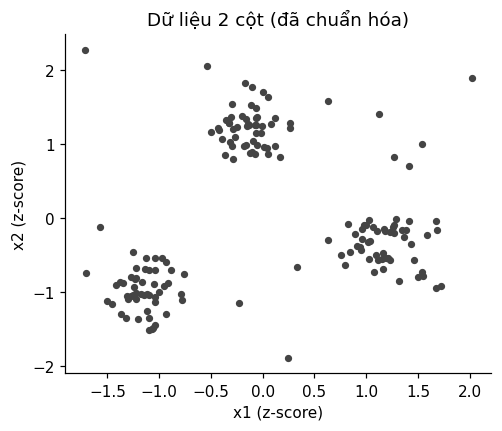

In [2]:
rng = np.random.default_rng(SEED)
X_blobs, truth = make_blobs(n_samples=150, centers=[(-4, -3), (0, 4), (5, -1)],
                            cluster_std=[0.9, 0.8, 1.0], random_state=SEED)
X_noise = rng.uniform(low=[-8, -7], high=[9, 8], size=(12, 2))
X = StandardScaler().fit_transform(np.vstack([X_blobs, X_noise]))
print("Kích thước dữ liệu:", X.shape)

fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(X[:, 0], X[:, 1], s=14, c="#444444")
ax.set_title("Dữ liệu 2 cột (đã chuẩn hóa)")
ax.set_xlabel("x1 (z-score)")
ax.set_ylabel("x2 (z-score)")
plt.show()

## 2. K-Means và chọn k

Các bước trong slide: chọn k, đặt k tâm, gán điểm về tâm gần nhất, cập nhật tâm,
lặp đến khi không đổi. Chọn k bằng WCSS (tổng bình phương khoảng cách trong cụm —
càng nhỏ càng khít) và silhouette (càng gần 1 càng tách rõ).

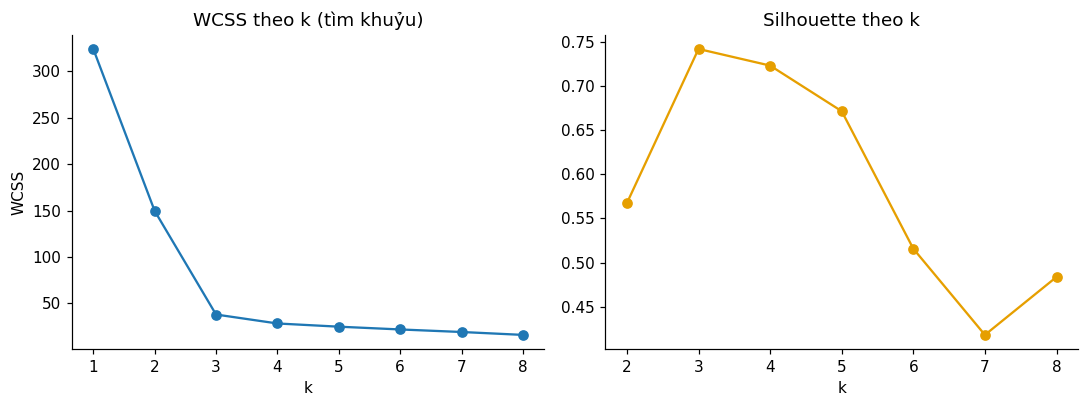

k có silhouette cao nhất: 3


In [3]:
ks = range(1, 9)
wcss = [KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X).inertia_ for k in ks]
sil = [silhouette_score(X, KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X))
       for k in ks if k > 1]

fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.8))
a.plot(list(ks), wcss, "o-")
a.set_title("WCSS theo k (tìm khuỷu)")
a.set_xlabel("k")
a.set_ylabel("WCSS")
b.plot([k for k in ks if k > 1], sil, "o-", color="#E69F00")
b.set_title("Silhouette theo k")
b.set_xlabel("k")
plt.tight_layout()
plt.show()
best_k = [k for k in ks if k > 1][int(np.argmax(sil))]
print("k có silhouette cao nhất:", best_k)

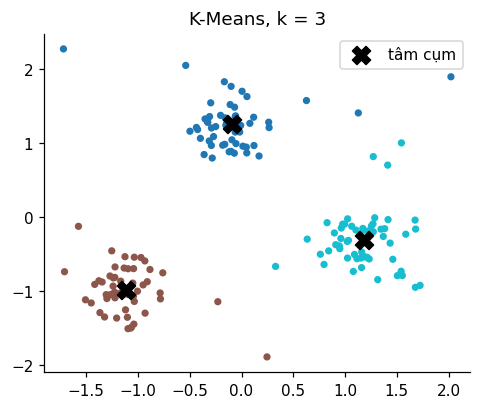

In [4]:
km = KMeans(n_clusters=best_k, n_init=10, random_state=SEED).fit(X)
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(X[:, 0], X[:, 1], c=km.labels_, cmap="tab10", s=14)
ax.scatter(*km.cluster_centers_.T, marker="X", s=140, c="black", label="tâm cụm")
ax.set_title(f"K-Means, k = {best_k}")
ax.legend()
plt.show()

## 3. Hierarchical clustering (agglomerative)

Bắt đầu mỗi điểm là một cụm, ghép hai cụm gần nhất, lặp đến còn một cụm. Khoảng cách
giữa hai cụm có bốn cách trong slide: điểm gần nhất (`single`), điểm xa nhất
(`complete`), khoảng cách tâm (`centroid`), trung bình các cặp điểm (`average`).
Thêm `ward` vì hay dùng trong thực tế. Dendrogram ghi thứ tự và độ cao (khoảng cách)
của từng lần ghép.

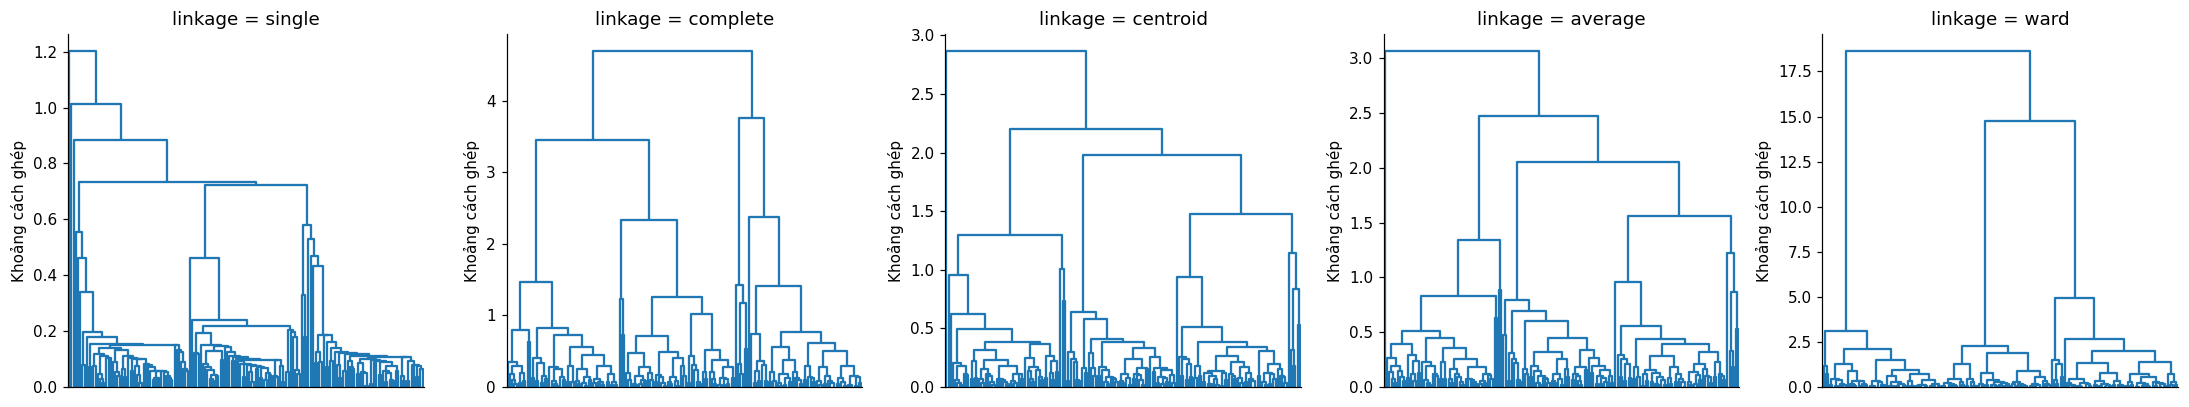

In [5]:
methods = ["single", "complete", "centroid", "average", "ward"]
fig, axes = plt.subplots(1, 5, figsize=(20, 3.8), sharey=False)
for ax, method in zip(axes, methods):
    Z = linkage(X, method=method)
    dendrogram(Z, ax=ax, no_labels=True, color_threshold=0)
    ax.set_title(f"linkage = {method}")
    ax.set_ylabel("Khoảng cách ghép")
plt.tight_layout()
plt.show()

### Chọn số cụm từ dendrogram

Mẹo của slide: cắt ở chỗ có bước nhảy khoảng cách lớn nhất. Với `ward`, tìm khoảng
trống dọc lớn nhất giữa hai lần ghép liên tiếp.

Bước nhảy lớn nhất ở lần ghép thứ 159 → k = 3


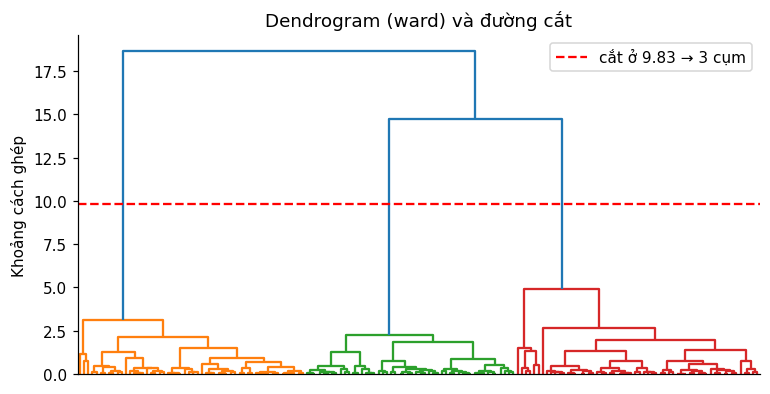

In [6]:
Z = linkage(X, method="ward")
heights = Z[:, 2]
gaps = np.diff(heights)
n = X.shape[0]
cut = int(np.argmax(gaps))
k_dendro = n - (cut + 1)
threshold = (heights[cut] + heights[cut + 1]) / 2
print(f"Bước nhảy lớn nhất ở lần ghép thứ {cut + 1} → k = {k_dendro}")

fig, ax = plt.subplots(figsize=(8, 4))
dendrogram(Z, ax=ax, no_labels=True, color_threshold=threshold)
ax.axhline(threshold, color="red", ls="--", label=f"cắt ở {threshold:.2f} → {k_dendro} cụm")
ax.set_title("Dendrogram (ward) và đường cắt")
ax.set_ylabel("Khoảng cách ghép")
ax.legend()
plt.show()

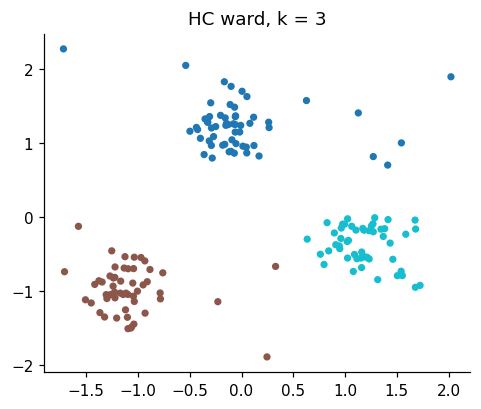

In [7]:
hc = AgglomerativeClustering(n_clusters=k_dendro, linkage="ward").fit(X)
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(X[:, 0], X[:, 1], c=hc.labels_, cmap="tab10", s=14)
ax.set_title(f"HC ward, k = {k_dendro}")
plt.show()

## 4. Đặt STING lên cùng dữ liệu

STING không cần chọn k. Nó chia không gian thành lưới, đếm điểm trong ô, gom các ô
dày kề nhau thành cụm; điểm ở ô thưa là nhiễu (-1). K-Means và HC thì gán mọi điểm
vào một cụm, kể cả nhiễu.

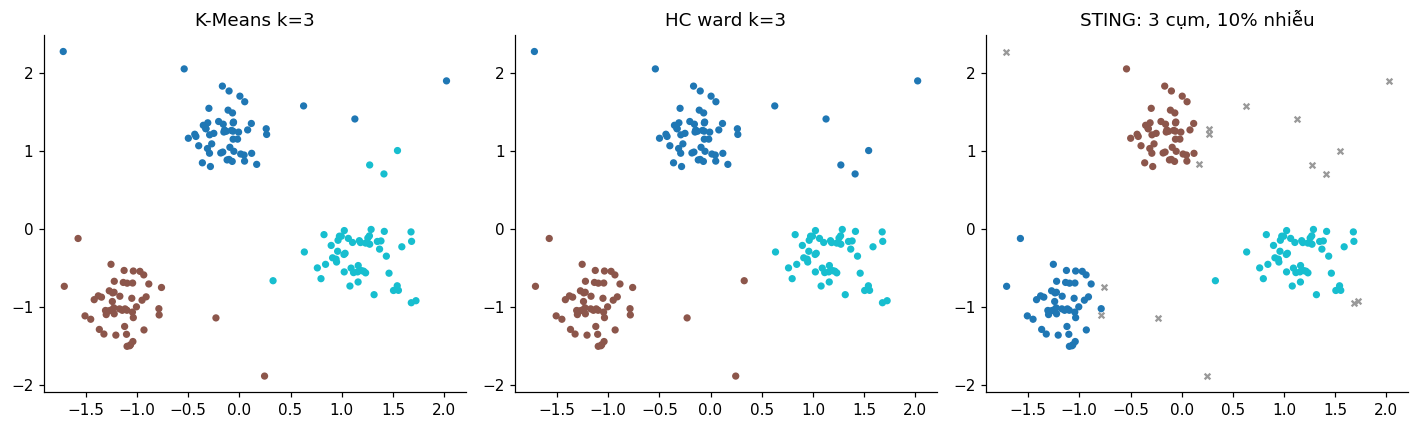

In [8]:
sting = STING(n_levels=3, factor=4, min_count=4).fit(X)
labels = sting.cluster(level=1, connectivity=1)  # lưới 4 × 4
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, lab, title in ((axes[0], km.labels_, f"K-Means k={best_k}"),
                       (axes[1], hc.labels_, f"HC ward k={k_dendro}"),
                       (axes[2], labels, f"STING: {sting.n_clusters_} cụm, "
                                         f"{(labels == -1).mean():.0%} nhiễu")):
    noise = lab == -1
    ax.scatter(X[noise, 0], X[noise, 1], c="#999999", marker="x", s=14)
    ax.scatter(X[~noise, 0], X[~noise, 1], c=lab[~noise], cmap="tab10", s=14)
    ax.set_title(title)
plt.tight_layout()
plt.show()

## Tóm tắt để nhớ

| | K-Means | HC | STING |
|---|---|---|---|
| Cần chọn k trước | Có | Không (cắt dendrogram sau) | Không (tham số lưới, ngưỡng) |
| Ý tưởng | Tâm cụm | Ghép dần cụm gần nhau | Đếm điểm theo ô lưới |
| Nhiễu | Không có nhãn nhiễu | Không có nhãn nhiễu | Có (-1) |
| Cụm hình dạng | Lồi, tròn | Phụ thuộc linkage | Ghép được ô liền kề |